<a href="https://colab.research.google.com/github/tio22-png/Praktikum_PCVK_Hanggoro/blob/main/Modul1_PCVK_Hanggoro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jawaban Pertanyaan D2:
1. Eksekusi menggunakan Google Colab karena berbasis cloud gratis, tidak perlu instalasi lokal, dan menyediakan akses GPU untuk mengolah citra.

2. Kegunaan library: Numpy untuk manipulasi array, Pandas untuk analisis data, cv2 untuk pengolahan citra (OpenCV), skimage untuk pemrosesan gambar, dan matplotlib untuk visualisasi. Tidak semua harus digunakan bersamaan, cukup di-import sesuai kebutuhan eksekusi.

3. cv.resize digunakan untuk mengubah ukuran gambar menjadi 0,5x lipat (setengah ukuran asli). Jika tidak digunakan, gambar akan dimuat dalam resolusi aslinya yang mungkin terlalu besar dan memakan memori.

4. [255,255,255] adalah nilai representasi warna putih dalam format RGB/BGR.

5. Semakin tinggi resolusi gambar, semakin banyak jumlah pixel di dalamnya, sehingga informasi detail gambar semakin tajam dan jelas.

Jawaban Pertanyaan D3:

1. Menampilkan tanpa matplotlib (misal pakai cv2_imshow) hanya menampilkan gambar saja. Menampilkan dengan matplotlib (pakai plt.imshow) akan menampilkan gambar beserta sumbu koordinat (X dan Y) yang memudahkan kita melihat ukuran dan letak pixel.

2. Tipe data int16 dan int32 menentukan kapasitas memori yang dialokasikan. Pada fungsi tertentu di OpenCV seperti membuat polyline, library mewajibkan format array 32-bit (int32) agar bisa digambar dengan presisi.

3. from google.colab.patches import cv2_imshow digunakan karena fungsi asli cv2.imshow dari OpenCV diblokir oleh Colab (bisa bikin crash browser). Fungsi pengganti ini membuat gambar aman ditampilkan di browser Colab.

4. from skimage import io menyediakan fungsi Input/Output untuk membaca file citra, khususnya untuk langsung memuat gambar dari link URL web (io.imread).

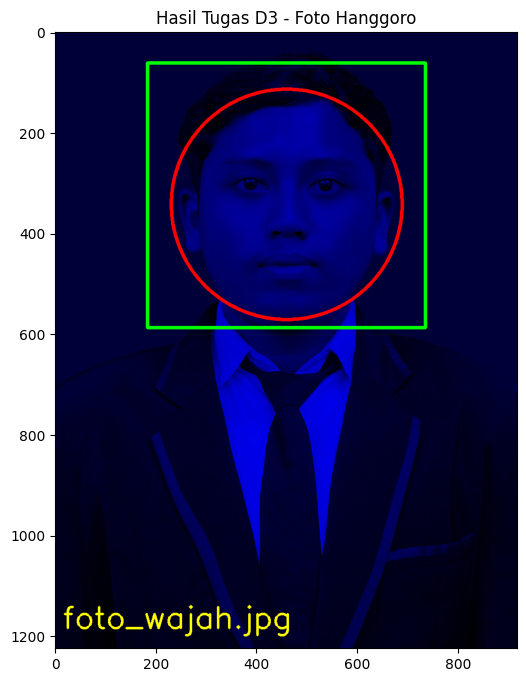

In [6]:
import cv2
import random
import matplotlib.pyplot as plt

# 1. Buka foto diri Anda
img = cv2.imread('foto_wajah.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
tinggi, lebar = img.shape[:2]

# Tugas 1-4: Manipulasi Channel dan Crop
img_rb = img.copy()
img_rb[:, :, 1] = 0 # Red-Blue (Green di-nol-kan)
img_red_crop = img[5:30, :, 0] # Baris 5-30, semua kolom, channel Red

# Tugas 5: 5 Kotak random
img_kotak = img.copy()
for i in range(5):
    x1, y1 = random.randint(0, lebar-50), random.randint(0, tinggi-50)
    x2, y2 = random.randint(x1+10, lebar), random.randint(y1+10, tinggi)
    cv2.rectangle(img_kotak, (x1, y1), (x2, y2), (random.randint(0,255), random.randint(0,255), random.randint(0,255)), 3)

# Tugas 6: Posisi Terbalik
img_terbalik = cv2.flip(img, -1)

# Tugas 7, 8, 9: Kotak di wajah, Channel Blue, dan Nama
img_tugas_akhir = img.copy()
img_tugas_akhir[:, :, 0] = 0 # Matikan Red
img_tugas_akhir[:, :, 1] = 0 # Matikan Green

# === KOORDINAT KHUSUS WAJAH HANGGORO ===
# Menghitung koordinat kotak pas di area kepala hingga leher
wajah_x1, wajah_y1 = int(lebar * 0.20), int(tinggi * 0.05)
wajah_x2, wajah_y2 = int(lebar * 0.80), int(tinggi * 0.48)
cv2.rectangle(img_tugas_akhir, (wajah_x1, wajah_y1), (wajah_x2, wajah_y2), (0, 255, 0), 5)

# Menghitung koordinat lingkaran pas di tengah wajah
center_x, center_y = int(lebar * 0.50), int(tinggi * 0.28)
radius = int(lebar * 0.25)
cv2.circle(img_tugas_akhir, (center_x, center_y), radius, (255, 0, 0), 5)
# =======================================

# Beri nama file di pojok kiri bawah
cv2.putText(img_tugas_akhir, 'foto_wajah.jpg', (15, tinggi-40), cv2.FONT_HERSHEY_SIMPLEX, 2, (255, 255, 0), 4)

# Menampilkan Hasil
plt.figure(figsize=(8,8))
plt.imshow(img_tugas_akhir)
plt.title("Hasil Tugas D3 - Foto Hanggoro")
plt.show()

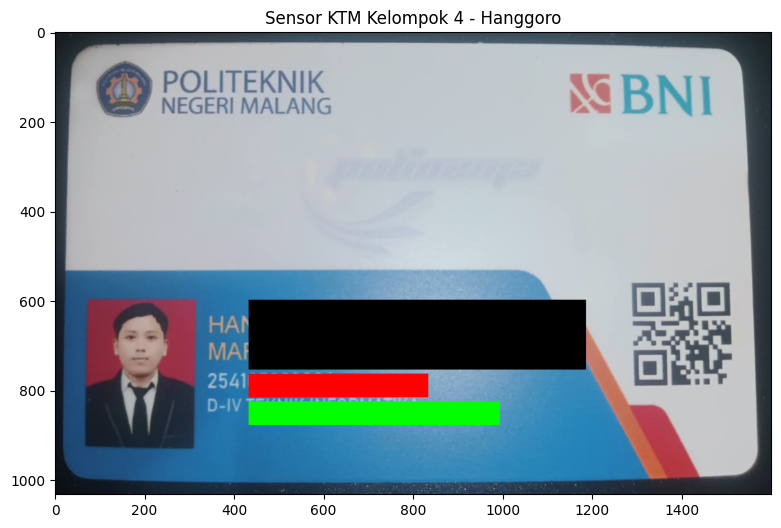

In [7]:
import cv2
import matplotlib.pyplot as plt

# Buka gambar KTM
ktm = cv2.imread('KTM.jpg')
ktm = cv2.cvtColor(ktm, cv2.COLOR_BGR2RGB)
tinggi_ktm, lebar_ktm = ktm.shape[:2]

# === KOORDINAT KHUSUS SENSOR KTM HANGGORO ===
# 1. Menutup area NAMA (Hanggoro Nursetio Margono) - Warna Hitam
nama_pt1 = (int(lebar_ktm * 0.27), int(tinggi_ktm * 0.58))
nama_pt2 = (int(lebar_ktm * 0.74), int(tinggi_ktm * 0.73))
cv2.rectangle(ktm, nama_pt1, nama_pt2, (0, 0, 0), -1)

# 2. Menutup area NIM (254107023006) - Warna Merah
nim_pt1 = (int(lebar_ktm * 0.27), int(tinggi_ktm * 0.74))
nim_pt2 = (int(lebar_ktm * 0.52), int(tinggi_ktm * 0.79))
cv2.rectangle(ktm, nim_pt1, nim_pt2, (255, 0, 0), -1)

# 3. Menutup area PRODI (D-IV Teknik Informatika) - Warna Hijau
prodi_pt1 = (int(lebar_ktm * 0.27), int(tinggi_ktm * 0.80))
prodi_pt2 = (int(lebar_ktm * 0.62), int(tinggi_ktm * 0.85))
cv2.rectangle(ktm, prodi_pt1, prodi_pt2, (0, 255, 0), -1)
# =============================================

# Menampilkan Hasil Sensor
plt.figure(figsize=(10,6))
plt.imshow(ktm)
plt.title("Sensor KTM Kelompok 4 - Hanggoro")
plt.show()

Hasil Tugas Praktikum D2:


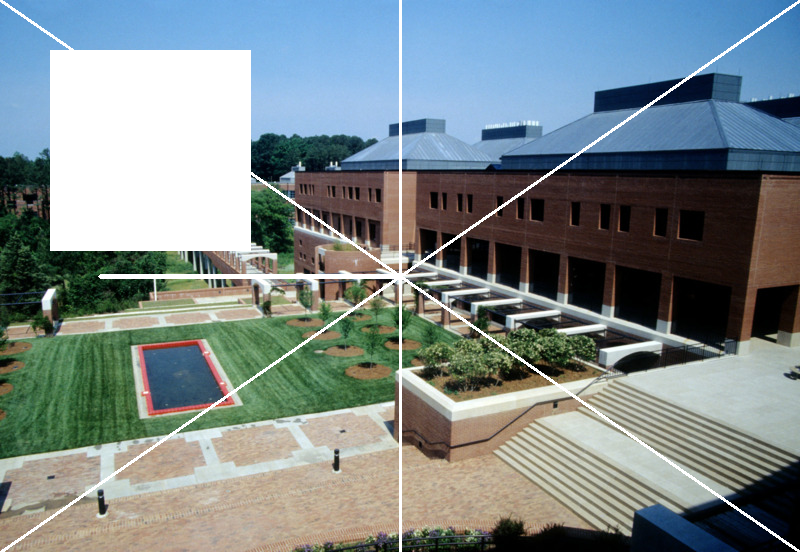

In [3]:
import numpy as np
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io

# Load image dari URL (URL diganti menggunakan gambar kampus NCSU dari modul agar tidak error)
url = "https://iiif.lib.ncsu.edu/iiif/0052574/full/800,/0/default.jpg"
image = io.imread(url)
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)

img_tugas = image.copy()
tinggi = img_tugas.shape[0]
lebar = img_tugas.shape[1]

# 1 & 2. Garis vertikal dan diagonal
cv.line(img_tugas, (int(lebar/2), 0), (int(lebar/2), tinggi), (255,255,255), 2)
cv.line(img_tugas, (0, 0), (lebar, tinggi), (255,255,255), 2)
cv.line(img_tugas, (lebar, 0), (0, tinggi), (255,255,255), 2)

# 3. Garis horizontal di tengah
cv.line(img_tugas, (100, int(tinggi/2)), (400, int(tinggi/2)), (255,255,255), 4)

# 4. Kotak pixel putih
cv.rectangle(img_tugas, (50, 50), (250, 250), (255,255,255), -1)

print("Hasil Tugas Praktikum D2:")
cv2_imshow(img_tugas)